# Food Delivery Time Prediction Model

## Libraries Used for the Project

In [1]:

# importing library used in the project
import pandas as pd
import statsmodels.api as sm # For Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor # For Variance Infaltion Factor (VIF)

import numpy as np

import janitor # For Data Cleaning

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import datasets, linear_model, metrics
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error # For MAE evaluation
from sklearn.metrics import root_mean_squared_error # For RMSE evaluation
from sklearn.metrics import r2_score # For R2 evaluation

from scipy.stats import chi2_contingency # For chi-squared test

import seaborn as sns

import geopy # For feature engineering calculation distance using coordinates
from geopy.distance import geodesic

import warnings
warnings.filterwarnings("ignore")

## Read & Prepare Data

In [2]:

# Load the data to python and check the data through sample
df = pd.read_csv('Food_Delivery_Time_Dataset.csv')
df.sample(4)

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
27623,0x598b,MUMRES13DEL01,37,4.7,19.178321,72.834715,19.248321,72.904715,02-04-2022,22:45:00,22:50:00,conditions Windy,Low,0,Drinks,motorcycle,NaN,No,Metropolitian,(min) 23
44093,0xd023,AGRRES07DEL03,23,5,27.160934,78.044095,27.220934,78.104095,15-02-2022,19:20:00,19:35:00,conditions Fog,Jam,0,Meal,motorcycle,1,No,Metropolitian,(min) 23
18513,0x2ef6,HYDRES07DEL01,35,5,17.424114,78.347554,17.494114,78.417554,23-03-2022,00:00:00,00:15:00,conditions Cloudy,Low,2,Buffet,scooter,1,No,Metropolitian,(min) 30
24843,0xc098,KOCRES19DEL03,23,4.2,-9.960846,76.293936,10.050846,76.383936,18-02-2022,20:35:00,20:50:00,conditions Cloudy,Jam,1,Meal,motorcycle,1,No,Metropolitian,(min) 42


In [3]:

# Check for data structure and type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [4]:

# Check for the number of rows and columns
df.shape

(45593, 20)

In [5]:

# Preliminary preparation

# Standardize the column name
df_clean = df.clean_names()

# Change column name to improve readability
df_clean = df_clean.rename(columns={'time_orderd': 'time_ordered', 'weatherconditions': 'weather_conditions'}) 

# Remove the substring "condition " from the weather_conditions column
df_clean['weather_conditions'] = df_clean['weather_conditions'].str.replace('conditions ', '', regex=False)

# Remove the substring "(min) " from the time_taken_min_ column
df_clean['time_taken_min_'] = df_clean['time_taken_min_'].str.replace('(min) ', '', regex=False)

# Remove whitespace in data
df_clean = df_clean.map(lambda x: x.strip() if isinstance(x, str) else x)

In [6]:

# check for duplicate row
print(df_clean.duplicated().sum())

0


In [7]:

# Deleting row that contain "Nan"

# Identify cells containing the string "NaN"
nan_mask = df_clean.map(lambda x: x == 'NaN')

# Filter out rows where any cell contains the string "NaN"
df_clean = df_clean[~nan_mask.any(axis=1)]

In [8]:

# Changing Dtypes to appropriate type 

df_clean['delivery_person_age'] = df_clean['delivery_person_age'].astype('int64')

df_clean['delivery_person_ratings'] = df_clean['delivery_person_ratings'].astype('float64')

df_clean['order_date'] = pd.to_datetime(df_clean['order_date'], format = '%d-%m-%Y', errors='coerce')

df_clean['time_ordered'] =  pd.to_timedelta(df_clean['time_ordered'])

df_clean['time_order_picked'] =  pd.to_timedelta(df_clean['time_order_picked'])

df_clean['vehicle_condition'] = df_clean['vehicle_condition'].astype('object')

df_clean['time_taken_min_'] = df_clean['time_taken_min_'].astype('int64')

# Columns to convert to lowercase
columns_to_standardize = ['weather_conditions', 'road_traffic_density', 'type_of_order',
                          'type_of_vehicle', 'festival', 'city']

df_clean[columns_to_standardize] = df_clean[columns_to_standardize].apply(lambda x: x.str.lower())

# Fix typo in the 'City' column
df_clean['city'] = df_clean['city'].replace('metropolitian', 'metropolitan')

df_clean.info() # Check if Dtypes changes success

<class 'pandas.core.frame.DataFrame'>
Index: 41368 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype          
---  ------                       --------------  -----          
 0   id                           41368 non-null  object         
 1   delivery_person_id           41368 non-null  object         
 2   delivery_person_age          41368 non-null  int64          
 3   delivery_person_ratings      41368 non-null  float64        
 4   restaurant_latitude          41368 non-null  float64        
 5   restaurant_longitude         41368 non-null  float64        
 6   delivery_location_latitude   41368 non-null  float64        
 7   delivery_location_longitude  41368 non-null  float64        
 8   order_date                   41368 non-null  datetime64[ns] 
 9   time_ordered                 41368 non-null  timedelta64[ns]
 10  time_order_picked            41368 non-null  timedelta64[ns]
 11  weather_conditions           4136

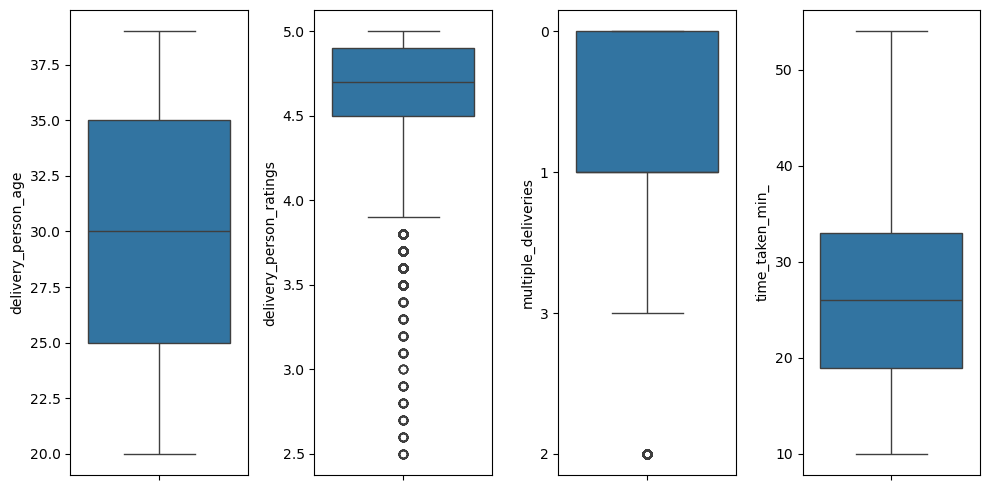

In [9]:

# Handling outlier (1)

# Using box plot to check for outlier
selected_cols = ['delivery_person_age', 'delivery_person_ratings', 'multiple_deliveries', 'time_taken_min_']

plt.figure(figsize = (10,5))
for i in range(len(selected_cols)):
    plt.subplot(1,len(selected_cols),i+1)
    sns.boxplot(df_clean[selected_cols[i]], orient = "v")
    plt.tight_layout()

In [10]:

# Handling outlier (2)

# Using IQR method for 'delivery_person_age' 
q1_age = df_clean['delivery_person_age'].quantile(0.25)
q3_age = df_clean['delivery_person_age'].quantile(0.75)

iqr_age = q3_age-q1_age 
fence_low_age  = q1_age-1.5*iqr_age
fence_high_age = q3_age+1.5*iqr_age

# Filter out row that have outlier for 'delivery_person_age'
df_clean = df_clean[(df_clean['delivery_person_age'] >= fence_low_age) & (df_clean['delivery_person_age'] <= fence_high_age)]


# Using IQR method for 'delivery_person_ratings' 
q1_delivery = df_clean['delivery_person_ratings'].quantile(0.25)
q3_delivery = df_clean['delivery_person_ratings'].quantile(0.75)

iqr_delivery = q3_delivery-q1_delivery 
fence_low_delivery  = q1_delivery-1.5*iqr_delivery
fence_high_delivery = q3_delivery+1.5*iqr_delivery

# Filter out row that have outlier for 'delivery_person_ratings'
df_clean = df_clean[(df_clean['delivery_person_ratings'] >= fence_low_delivery) & (df_clean['delivery_person_ratings'] <= fence_high_delivery)]


# Using IQR method for 'time_taken_min_' 
q1_time = df_clean['time_taken_min_'].quantile(0.25)
q3_time = df_clean['time_taken_min_'].quantile(0.75)

iqr_time = q3_time-q1_time 
fence_low_time  = q1_time-1.5*iqr_time
fence_high_time = q3_time+1.5*iqr_time

# Filter out row that have outlier for 'delivery_person_ratings'
df_clean = df_clean[(df_clean['time_taken_min_'] >= fence_low_time) & (df_clean['time_taken_min_'] <= fence_high_time)]

In [11]:

# Handling abnormal value (1)

# Filter out abnormal restaurant coordinate (0,0) which is null island (https://en.wikipedia.org/wiki/Null_Island)
df_clean=df_clean.query('restaurant_latitude != 0 & restaurant_longitude != 0')

In [12]:

# Handling abnormal value (2)

# Check 'delivery_person_age' for abnormal values
df_clean['delivery_person_age'].describe()

count    36822.000000
mean        29.529222
std          5.762479
min         20.000000
25%         25.000000
50%         30.000000
75%         35.000000
max         39.000000
Name: delivery_person_age, dtype: float64

In [13]:

# Handling abnormal value (3)

# Check 'delivery_person_ratings' for abnormal values
df_clean['delivery_person_ratings'].describe()

count    36822.000000
mean         4.663565
std          0.254925
min          3.900000
25%          4.600000
50%          4.700000
75%          4.900000
max          5.000000
Name: delivery_person_ratings, dtype: float64

## EXPLORATORY DATA ANALYSIS (EDA)

In [14]:

# calculate mean and median for delivery time
mean = df_clean['time_taken_min_'].mean()
median = df_clean['time_taken_min_'].median()

print(f"Mean delivery time: {mean:.2f} minutes")
print(f"Median delivery time: {median:.2f} minutes")

Mean delivery time: 26.13 minutes
Median delivery time: 25.00 minutes


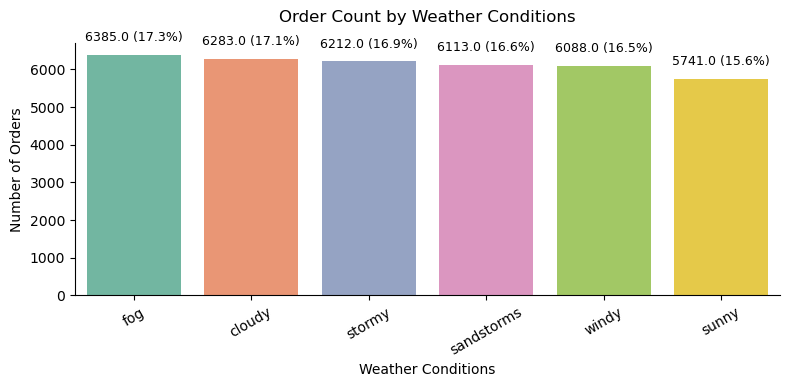

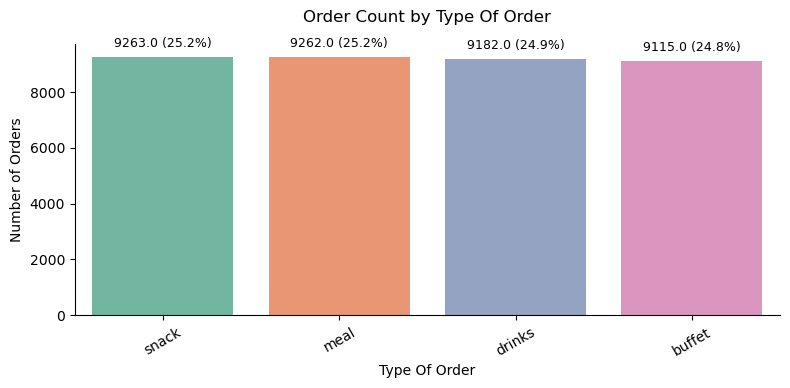

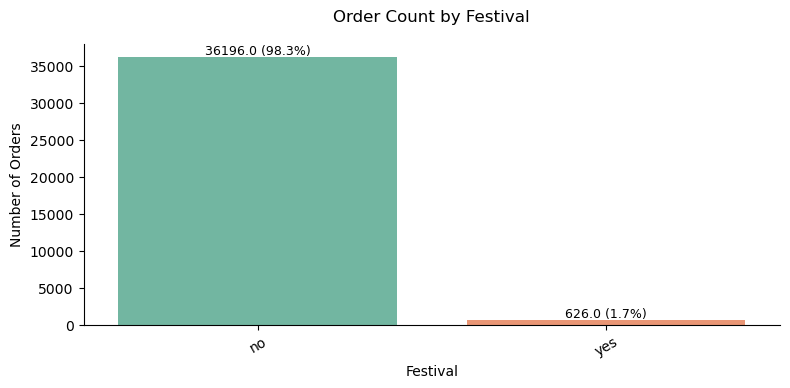

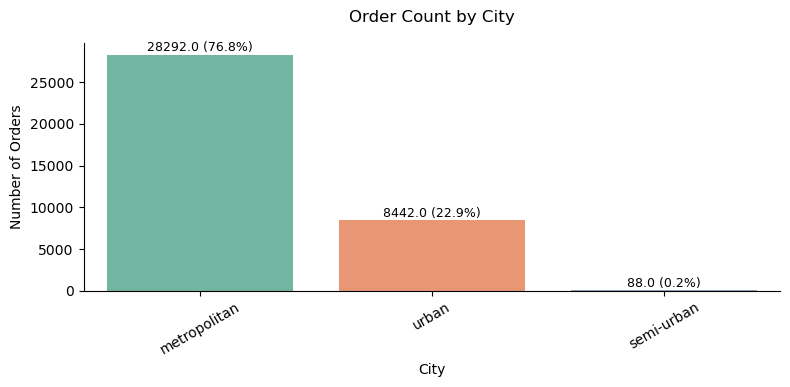

In [15]:


# List of categorical columns to plot
categorical_cols = ['weather_conditions', 'type_of_order', 'festival', 'city']

# Create separate bar plots
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    ax = sns.countplot(data=df_clean, x=col, order=df_clean[col].value_counts().index, palette='Set2')
    plt.title(f'Order Count by {col.replace("_", " ").title()}', y=1.05)  # <-- raises title
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Number of Orders')
    plt.xticks(rotation=30)

    # Total count to compute percentages
    total = len(df_clean)

    # Add count and percentage labels
    for p in ax.patches:
        count = p.get_height()
        percent = 100 * count / total
        label = f'{count} ({percent:.1f}%)'
        ax.text(p.get_x() + p.get_width() / 2., count + total * 0.01,  # small vertical offset
                label, ha='center', fontsize=9)


    # Remove top and right spines
    sns.despine()  # <-- this does the trick

    plt.tight_layout()
    plt.show()

In [16]:

# Run chi-squared test to know if there any significant difference for each type of weather
weather_counts = df_clean['weather_conditions'].value_counts()
chi2, p, _, _ = chi2_contingency([weather_counts.values])
print(f'p-value: {p}')

p-value: 1.0



### Effect of weather on the number of order

based on the result of chi squared test there's no statistically significant difference in the number of orders between weather categories. but the number of order in the sunny weather is slightly lower this could be due to:
- People feel less hungry when it's hot — less demand for heavy meals or hot foods
- People go out more during sunny days therefore reducing online delivery demand

In [17]:
# Run chi-squared test to know if there any significant difference for each type of order
type_of_order_counts = df_clean['type_of_order'].value_counts()
chi2, p, _, _ = chi2_contingency([type_of_order_counts.values])
print(f'p-value: {p}')

p-value: 1.0



### Type of Order 

based on the result of chi squared test there's no statistically significant difference in the type of orders categories. This could indicate:
- Consumers are using the app consistently across all food types — snacks, meals, drinks, and buffets.
- The app likely serves as a general-purpose delivery platform, not biased toward one type of order.
- It could reflect good category balance in:
  - User demand (people want variety)
  - App design (equal visibility/promotion of categories)
  - Availability (restaurants support all types)


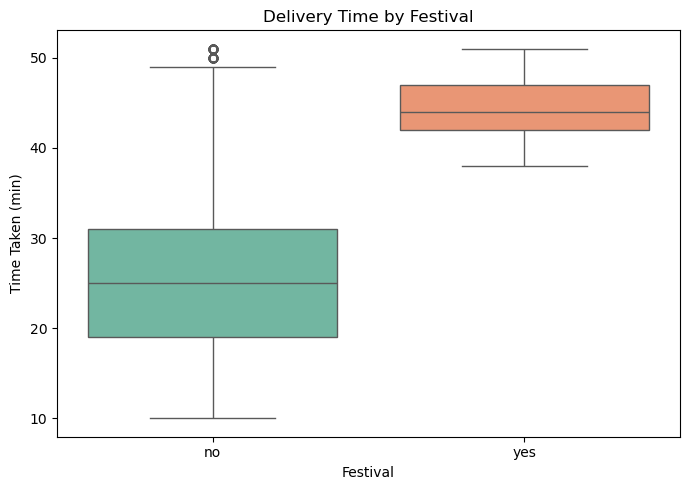

In [ ]:

# Create bar plot for delivery time based on festival occurence criteria
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x='festival', y='time_taken_min_', palette='Set2')
plt.title('Delivery Time by Festival')
plt.xlabel('Festival')
plt.ylabel('Time Taken (min)')
plt.tight_layout()
plt.show()

Despite a low order volume, delivery times are substantially longer during festivals, which suggests logistical delays.

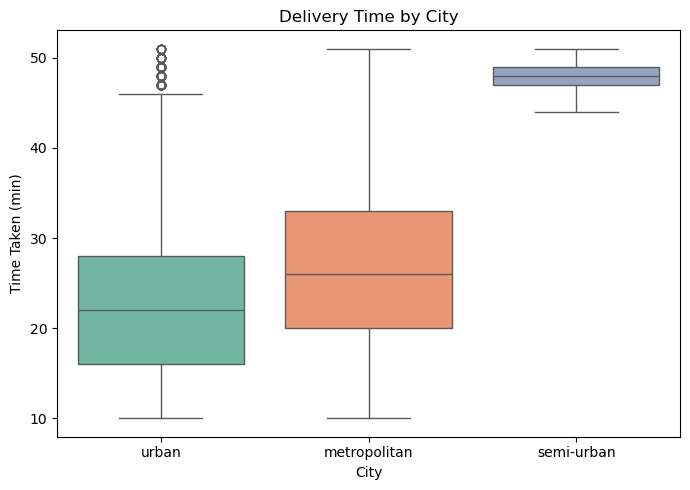

In [19]:

# Create bar plot for delivery time based on city criteria
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x='city', y='time_taken_min_', palette='Set2')
plt.title('Delivery Time by City')
plt.xlabel('City')
plt.ylabel('Time Taken (min)')
plt.tight_layout()
plt.show()

Semi-urban areas have the longest and most reliable delivery times, even though they receive less than 1% of orders; this suggests that there is insufficient infrastructure or operational coverage in these areas.
On the other hand, the shortest median delivery times are found in urban areas, indicating that these areas are currently the most efficient. But since they only account for about 23% of all orders, cities might offer an unrealised growth potential that combines operational effectiveness with potential for market expansion.
Even though they handle the majority of volume, metropolitan areas exhibit more delivery time variability, which suggests that route planning or time-based logistics may need to be optimised.

## FEATURE ENGINEERING

In [14]:

# Calculating distance using the restaurant and delivery location coordinates utilising the geopy library
df_clean['distance_km'] = df_clean[['restaurant_latitude', 
                                    'restaurant_longitude', 
                                    'delivery_location_latitude', 
                                    'delivery_location_longitude']].apply(
    lambda row: geodesic(row[0:2], row[2:4]).km, axis=1)

In [20]:

# Generate name of the day from date
df_clean['day_name'] = df_clean['order_date'].dt.day_name()

# Create a new column for weekday/weekend label
weekend = [('Weekend' if day in ['Saturday', 'Sunday'] else 'Weekday') for day in df_clean['day_name']]
df_clean['day_type'] = weekend

In [15]:

# Calculate pickup_period
df_clean['pickup_period'] = df_clean['time_order_picked'] - df_clean['time_ordered']

df_clean['pickup_period'] = df_clean['pickup_period'].apply(lambda x: x + pd.Timedelta(days=1) if x < pd.Timedelta(days=0) else x)

In [16]:

# Grouping the order time

# Function to create label
def label_time(td):
    total_seconds = td.total_seconds()
    hours = (total_seconds // 3600) % 24  # Extract hours from timedelta
    if 6 <= hours < 12:
        return 'Breakfast'
    elif 12 <= hours < 16:
        return 'Lunch'
    elif 16 <= hours < 21:
        return 'Dinner'
    else:
        return 'Late Night'

# Apply the function to create a new column
df_clean['ordered_class'] = df_clean['time_ordered'].apply(label_time)

In [17]:

# Handling outlier for numeric feature 

# Using IQR method for 'distance_km' 
q1_dist = df_clean['distance_km'].quantile(0.25)
q3_dist = df_clean['distance_km'].quantile(0.75)

iqr_dist = q3_dist-q1_dist 
fence_low_dist  = q1_dist-1.5*iqr_dist
fence_high_dist = q3_age+1.5*iqr_dist

# Filter out row that have outlier for 'distance_km'
df_clean = df_clean[(df_clean['distance_km'] >= fence_low_dist) & (df_clean['distance_km'] <= fence_high_dist)]


df_clean['distance_km'].describe()

count    36682.000000
mean         9.601562
std          5.582102
min          1.463837
25%          4.647989
50%          9.160879
75%         13.592749
max         20.942906
Name: distance_km, dtype: float64

In [21]:

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 36682 entries, 0 to 45592
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype          
---  ------                       --------------  -----          
 0   id                           36682 non-null  object         
 1   delivery_person_id           36682 non-null  object         
 2   delivery_person_age          36682 non-null  int64          
 3   delivery_person_ratings      36682 non-null  float64        
 4   restaurant_latitude          36682 non-null  float64        
 5   restaurant_longitude         36682 non-null  float64        
 6   delivery_location_latitude   36682 non-null  float64        
 7   delivery_location_longitude  36682 non-null  float64        
 8   order_date                   36682 non-null  datetime64[ns] 
 9   time_ordered                 36682 non-null  timedelta64[ns]
 10  time_order_picked            36682 non-null  timedelta64[ns]
 11  weather_conditions           3668

## One Hot Encoding for Object Type Feature

In [22]:

# Prepare one hot encoding for column with 'Object' Dtypes (1)

# Dropping unused column from df_clean
df_clean.drop(['id', 'delivery_person_id', 'delivery_person_age', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_ordered', 'time_order_picked', 'day_name'], axis = 1, inplace = True)


In [23]:

# Prepare one hot encoding for column with 'Object' Dtypes (2)

# One Hot Encoding
df_object = df_clean.select_dtypes(["object"])
obj_cols = list(df_object.columns)

df_result = pd.get_dummies(df_clean, columns = obj_cols)

df_result.sample (5)


,delivery_person_ratings,time_taken_min_,distance_km,pickup_period,weather_conditions_cloudy,weather_conditions_fog,weather_conditions_sandstorms,weather_conditions_stormy,weather_conditions_sunny,weather_conditions_windy,...,festival_yes,city_metropolitan,city_semi-urban,city_urban,ordered_class_Breakfast,ordered_class_Dinner,ordered_class_Late Night,ordered_class_Lunch,day_type_Weekday,day_type_Weekend
39631,4.7,16,10.579304,0 days 00:10:00,False,False,False,False,True,False,...,False,True,False,False,False,False,True,False,True,False
37890,4.7,15,6.196805,0 days 00:15:00,True,False,False,False,False,False,...,False,True,False,False,False,True,False,False,True,False
30418,4.3,49,12.271121,0 days 00:05:00,True,False,False,False,False,False,...,True,True,False,False,False,False,True,False,True,False
8610,4.9,30,8.976574,0 days 00:10:00,False,False,False,True,False,False,...,False,True,False,False,False,True,False,False,True,False
44348,4.9,28,19.844235,0 days 00:05:00,False,False,False,True,False,False,...,False,True,False,False,False,False,True,False,False,True


## Feature Selection

In [26]:

# Selecting features with correlation more than 0.1 or -0.1 to the time_taken_min_
correlation_matrix = df_result.corr()
target_variable = 'time_taken_min_'
target_correlation = correlation_matrix[target_variable].abs()
selected_features = target_correlation[target_correlation > 0.1].index.tolist()
df_selected = df_result[selected_features]

print(df_selected.columns)

Index(['delivery_person_ratings', 'time_taken_min_', 'distance_km',
       'weather_conditions_cloudy', 'weather_conditions_fog',
       'weather_conditions_sunny', 'road_traffic_density_jam',
       'road_traffic_density_low', 'vehicle_condition_0',
       'vehicle_condition_1', 'vehicle_condition_2',
       'type_of_vehicle_motorcycle', 'type_of_vehicle_scooter',
       'multiple_deliveries_0', 'multiple_deliveries_2',
       'multiple_deliveries_3', 'festival_no', 'festival_yes',
       'city_metropolitan', 'city_semi-urban', 'city_urban',
       'ordered_class_Breakfast', 'ordered_class_Dinner'],
      dtype='object')


In [27]:

# Variance Inflation Factor (VIF)

# Select numerical predictors
numerical_predictors = ['delivery_person_ratings', 'distance_km']

# Prepare the data for VIF calculation
calc_vif = df_clean[numerical_predictors]

# Add a constant for intercept (for VIF calculation)
calc_vif = sm.add_constant(calc_vif)

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Predictor'] = calc_vif.columns
vif_data['VIF'] = [variance_inflation_factor(calc_vif.values, i) for i in range(calc_vif.shape[1])]

print(vif_data)

                 Predictor         VIF
0                    const  341.626412
1  delivery_person_ratings    1.001642
2              distance_km    1.001642


##### Based on the VIF calculation result there is no multicollinearity issues for the numeric feature used in the model

## Split Train Test Data

In [28]:

# Splitting Train Test
y = df_selected['time_taken_min_']
X = df_selected.drop(columns = ['time_taken_min_'])

# stratified random splitting X and y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,
                                            random_state = 42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(29345, 22)
(7337, 22)
(29345,)
(7337,)


## Modelling

### Linear Regression Modelling

In [29]:

# Create linear regression object
linear_reg = linear_model.LinearRegression()

# Fit the model
linear_reg.fit(X_train, y_train)

# Coefficients and Intercept
print('Coefficients: ', linear_reg.coef_)
print('Intercept: ', linear_reg.intercept_)

Coefficients:  [-7.26159399  0.33289318  2.50123382  2.51327489 -3.66061277  2.02698656
 -5.65924127  2.83339116 -1.44203592 -1.39135524  0.09017712  0.17085035
 -2.17532602  6.96524822 10.58045983 -4.54479008  4.54479008 -2.23750959
  6.63474479 -4.39723519  1.58464663 -0.61234263]
Intercept:  65.08582948415419


### Linear Regression Model Evaluation

In [30]:

# Fit the test data into model
y_pred = linear_reg.predict(X_test)

# Mean Absolute Error (MAE)
MAE = mean_absolute_error(y_test, y_pred)

# Root Mean Squared Error (RMSE)
RMSE = root_mean_squared_error(y_test, y_pred)

# R2
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)

MAE  :  4.99676718121081
RMSE :  6.181564862384472
R2   :  0.53411528148029


### Ridge Regression Modelling with Hyperparameter Tuning

In [31]:

# Create ridge regression object 
ridge_reg = Ridge()

# Define the hyperparameter grid
params = {'alpha': np.logspace(-4, 4, 50)}

# Set up the GridSearchCV
grid_search = GridSearchCV(estimator = ridge_reg, param_grid = params, scoring = 'neg_mean_squared_error', cv=5)

# Fit the model
grid_search.fit(X_train, y_train)

# Get the best model
best_ridge = grid_search.best_estimator_

# Print the best alpha value
print(f"Best alpha: {grid_search.best_params_['alpha']}")

# Coefficients and Intercept
print('Coefficients: ', best_ridge.coef_)
print('Intercept: ', best_ridge.intercept_)

Best alpha: 0.3906939937054613
Coefficients:  [-7.2604545   0.3329064   2.50126013  2.51325021 -3.6605595   2.0274577
 -5.65885526  2.83355213 -1.44213906 -1.39141307  0.09035694  0.17082309
 -2.17556764  6.96300204 10.5604515  -4.54449626  4.54449626 -2.22671595
  6.61303354 -4.38631759  1.58443398 -0.61205255]
Intercept:  65.06919070641854


### Ridge Regression Model Evaluation

In [32]:

# Fit the test data into model
y_pred = best_ridge.predict(X_test)

# Mean Absolute Error (MAE)
MAE = mean_absolute_error(y_test, y_pred)

# Root Mean Squared Error (RMSE)
RMSE = root_mean_squared_error(y_test, y_pred)

# R2
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)

MAE  :  4.996794514926257
RMSE :  6.181576480946274
R2   :  0.534113530171163


### Lasso Regression Modelling with Hyperparameter Tuning

In [33]:

# Create lasso regression object 
lasso_reg = Lasso()

# Define the hyperparameter grid
params = {'alpha': np.logspace(-4, 4, 50)}

# Set up the GridSearchCV
grid_search = GridSearchCV(estimator = lasso_reg, param_grid = params, scoring = 'neg_mean_squared_error', cv=5)

# Fit the model
grid_search.fit(X_train, y_train)

# Get the best model
best_lasso = grid_search.best_estimator_

# Print the best alpha value
print(f"Best alpha: {grid_search.best_params_['alpha']}")

# Coefficients and Intercept
print('Coefficients: ', best_lasso.coef_)
print('Intercept: ', best_lasso.intercept_)

Best alpha: 0.0004498432668969444
Coefficients:  [-7.25720509  0.33273771  2.4988477   2.51071239 -3.65969782  2.02753129
 -5.6545875   4.22888307 -0.04587308 -0.          0.07578265  0.15576828
 -2.17505118  6.95785515 10.52579242 -9.07689453  0.          0.
  8.70149747 -2.15837403  1.57880633 -0.60794954]
Intercept:  65.97960715475591


### Lasso Regression Model Evaluation

In [34]:

# Fit the test data into model
y_pred = best_lasso.predict(X_test)

# Mean Absolute Error (MAE)
MAE = mean_absolute_error(y_test, y_pred)

# Root Mean Squared Error (RMSE)
RMSE = root_mean_squared_error(y_test, y_pred)

# R2
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)


MAE  :  4.996885811673846
RMSE :  6.181672314618077
R2   :  0.5340990846790548


### Random Forest Regression Model with Hyperparameter Tuning

In [35]:

# Create Random Forest regressor object
rf_reg = RandomForestRegressor()

# Define the hyperparameter grid
params = {
    'n_estimators': [100, 200, 300, 400, 500],  # Number of trees in the forest
    'max_features': ['auto', 'sqrt'],           # Number of features to consider at every split
    'max_depth': [10, 20, 30, 40, 50, None],    # Maximum number of levels in each decision tree
    'min_samples_split': [2, 5, 10],            # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4],              # Minimum number of samples required to be at a leaf node
    'bootstrap': [True, False]                  # Method of selecting samples for training each tree
}

# Set up the RandomizedSearchCV
random_search = RandomizedSearchCV(estimator=rf_reg, param_distributions=params, 
                                   n_iter=100, scoring='neg_mean_squared_error', cv=5, 
                                   verbose=1, random_state=42, n_jobs=-1)

# Fit the model
random_search.fit(X_train, y_train)

# Get the best model
best_rf = random_search.best_estimator_

# Print the best parameters
print(f"Best parameters: {random_search.best_params_}")

# Feature Importance
print('Feature Importances: ', best_rf.feature_importances_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters: {'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20, 'bootstrap': True}
Feature Importances:  [0.19245539 0.15033043 0.04920008 0.05126263 0.06590904 0.0620075
 0.12018468 0.07229114 0.00921968 0.00783096 0.00858932 0.00462943
 0.0277125  0.06099825 0.00971666 0.02581705 0.02756477 0.00826856
 0.0013728  0.01041661 0.01099264 0.02322987]


### Random Forest Regression Model Evaluation

In [36]:

# Fit the test data into model
y_pred = best_rf.predict(X_test)

# Evaluating Model
MAE = mean_absolute_error(y_test, y_pred)
RMSE = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)

MAE  :  3.8735795546800245
RMSE :  4.932127490581135
R2   :  0.703414310261631


## Split Train Test Data (Stratified Random Sampling)

In [38]:

# Splitting Train Test
y = df_selected['time_taken_min_']
X = df_selected.drop(columns = ['time_taken_min_'])

# Define the number of quantiles (strata)
n_quantiles = 13

# Create quantile groups
qcuts = pd.qcut(df_selected['time_taken_min_'], n_quantiles, labels = False)

# Stratified split using quantile groups
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,
                                                  stratify = qcuts,
                                                  random_state = 42)


### Linear Regression Modelling (Stratified)

In [39]:

# Create linear regression object
linear_reg = linear_model.LinearRegression()

# Fit the model
linear_reg.fit(X_train, y_train)

# Coefficients and Intercept
print('Coefficients: ', linear_reg.coef_)
print('Intercept: ', linear_reg.intercept_)

Coefficients:  [-7.35637699  0.33944766  2.59254685  2.5523418  -3.52225653  2.01197053
 -5.61595596  2.84300908 -1.42090591 -1.42210317  0.0833094   0.17085327
 -2.20421403  6.99885445 10.45197293 -4.65618617  4.65618617 -2.29938931
  6.66827511 -4.3688858   1.62272746 -0.63119681]
Intercept:  65.55774404418847


### Linear Regression Modelling (Stratified) Evaluation

In [40]:

# Fit the test data into model
y_pred = linear_reg.predict(X_test)

# Evaluating Model
MAE = mean_absolute_error(y_test, y_pred)
RMSE = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)


MAE  :  4.869066817619107
RMSE :  6.059298286740979
R2   :  0.5497969526781332


### Ridge Regression Modelling (STratified) with Hyperparameter Tuning

In [41]:

# Create ridge regression object 
ridge_reg = Ridge()

# Define the hyperparameter grid
params = {'alpha': np.logspace(-4, 4, 50)}

# Set up the GridSearchCV
grid_search = GridSearchCV(estimator = ridge_reg, param_grid = params, scoring = 'neg_mean_squared_error', cv=5)

# Fit the model
grid_search.fit(X_train, y_train)

# Get the best model
best_ridge = grid_search.best_estimator_

# Print the best alpha value
print(f"Best alpha: {grid_search.best_params_['alpha']}")

# Coefficients and Intercept
print('Coefficients: ', best_ridge.coef_)
print('Intercept: ', best_ridge.intercept_)

Best alpha: 0.0001
Coefficients:  [-7.35637669  0.33944766  2.59254687  2.55234179 -3.52225652  2.01197065
 -5.61595586  2.84300887 -1.42090619 -1.42210345  0.08330946  0.17085327
 -2.20421409  6.99885388 10.45196776 -4.65618606  4.65618606 -2.29938615
  6.66826938 -4.36888261  1.62272741 -0.63119673]
Intercept:  65.55773953383252


### Ridge Regression Modelling (Stratified) Evaluation

In [42]:

# Fit the test data into model
y_pred = best_ridge.predict(X_test)

# Evaluating Model
MAE = mean_absolute_error(y_test, y_pred)
RMSE = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)

MAE  :  4.869066827463705
RMSE :  6.059298288260466
R2   :  0.5497969524523387


### Lasso Regression Modelling (Stratified) with Hyperparameter Tuning

In [43]:

# Create lasso regression object 
lasso_reg = Lasso()

# Define the hyperparameter grid
params = {'alpha': np.logspace(-4, 4, 50)}

# Set up the GridSearchCV
grid_search = GridSearchCV(estimator = lasso_reg, param_grid = params, scoring = 'neg_mean_squared_error', cv=5)

# Fit the model
grid_search.fit(X_train, y_train)

# Get the best model
best_lasso = grid_search.best_estimator_

# Print the best alpha value
print(f"Best alpha: {grid_search.best_params_['alpha']}")

# Coefficients and Intercept
print('Coefficients: ', best_lasso.coef_)
print('Intercept: ', best_lasso.intercept_)

Best alpha: 0.0001
Coefficients:  [-7.35538294e+00  3.39417507e-01  2.59206535e+00  2.55178368e+00
 -3.52205064e+00  2.01207881e+00 -5.61494229e+00  4.26400285e+00
 -0.00000000e+00 -1.57478194e-03  8.05791568e-02  1.67844870e-01
 -2.20414889e+00  6.99718581e+00  1.04398143e+01 -9.30913063e+00
  0.00000000e+00  1.94433731e+00  1.08717321e+01 -1.24864486e-01
  1.62147489e+00 -6.30211565e-01]
Intercept:  64.54418592199266


### Lasso Regression Modelling (Stratified) Evaluation

In [44]:

# Fit the test data into model
y_pred = best_lasso.predict(X_test)

# Evaluating Model
MAE = mean_absolute_error(y_test, y_pred)
RMSE = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)

MAE  :  4.8690827428422665
RMSE :  6.059297498975968
R2   :  0.5497970697392742


### Random Forest Regression Model (Stratified) with Hyperparameter Tuning

In [45]:

# Create Random Forest regressor object
rf_reg = RandomForestRegressor()

# Define the hyperparameter grid
params = {
    'n_estimators': [100, 200, 300, 400, 500],  # Number of trees in the forest
    'max_features': ['auto', 'sqrt'],           # Number of features to consider at every split
    'max_depth': [10, 20, 30, 40, 50, None],    # Maximum number of levels in each decision tree
    'min_samples_split': [2, 5, 10],            # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4],              # Minimum number of samples required to be at a leaf node
    'bootstrap': [True, False]                  # Method of selecting samples for training each tree
}

# Set up the RandomizedSearchCV
random_search = RandomizedSearchCV(estimator=rf_reg, param_distributions=params, 
                                   n_iter=100, scoring='neg_mean_squared_error', cv=5, 
                                   verbose=1, random_state=42, n_jobs=-1)

# Fit the model
random_search.fit(X_train, y_train)

# Get the best model
best_rf = random_search.best_estimator_

# Print the best parameters
print(f"Best parameters: {random_search.best_params_}")

# Feature Importance
print('Feature Importances: ', best_rf.feature_importances_)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters: {'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 20, 'bootstrap': True}
Feature Importances:  [0.1970882  0.15566377 0.04990731 0.05105221 0.06031905 0.05648875
 0.12217806 0.07345669 0.00925801 0.00752235 0.00782349 0.00464343
 0.02841291 0.06056703 0.00993454 0.02397453 0.02835198 0.00835574
 0.0018293  0.00945832 0.01014634 0.02356798]


### Random Forest Regression Model (Stratified) Evaluation

In [46]:

# Fit the test data into model
y_pred = best_rf.predict(X_test)

# Evaluating Model
MAE = mean_absolute_error(y_test, y_pred)
RMSE = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


# Print the result
print('MAE  : ', MAE)
print('RMSE : ', RMSE)
print('R2   : ', r2)

MAE  :  3.8184245814522515
RMSE :  4.851750312678292
R2   :  0.7113572520510405
